# Serial correlation and the choice of volatility window (Binance trades)

*The code was written by an AI assistant (Claude) from my instructions; see [How this was made](../README.md#how-this-was-made).*

**Data period:** 9 to 18 March 2026, my first live capture (Binance only, 216.4 hours). The dates come from my notes.

Two questions I asked before building the conditional distribution grid (notebook 05):

* **A.** How long does short-term momentum last? (autocorrelation of 100 ms returns, and how often the next move
  has the same sign as the last one)
* **B.** Which trailing window gives the best separation between calm and wild volatility regimes, and is that
  separation stable over time?

**Data:** 32,017,772 Binance trades captured live over 216.4 hours (about 9 days) in March 2026.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SERVER = Path('data')   # folder that contains binance_spot/

def load_csvs(folder):
    dfs = []
    for f in sorted(Path(folder).glob('*.csv*')):
        try: dfs.append(pd.read_csv(f, on_bad_lines='skip'))
        except: pass
    return pd.concat(dfs, ignore_index=True) if dfs else pd.DataFrame()

bn_raw = load_csvs(SERVER / 'binance_spot')
bn_raw['local_ms'] = pd.to_numeric(bn_raw['local_ms'], errors='coerce')
bn_raw['price']    = pd.to_numeric(bn_raw['price'],    errors='coerce')
bn_raw = bn_raw.dropna(subset=['local_ms', 'price']).sort_values('local_ms').reset_index(drop=True)
bn_times  = bn_raw['local_ms'].values.astype(np.int64)
bn_prices = bn_raw['price'].values.astype(np.float64)

print(f'BN ticks: {len(bn_times):,}')
print(f'Time span: {(bn_times[-1] - bn_times[0]) / 3.6e6:.1f} hours')

BN ticks: 32,017,772
Time span: 216.4 hours


## Cell A — Momentum Duration
1. Bucket BN into 100ms bars (VWAP or last price)
2. Compute return autocorrelation at lags 100ms to 30s
3. Compute directional agreement rate vs horizon

Buckets: 7,791,612 (100ms each)
Valid returns: 7,791,611
Return std per 100ms: 0.1716 bps

  Lag (ms)  Lag (s)        ACF
────────────────────────────────
       100      0.1  +0.180064
       200      0.2  +0.079999
       300      0.3  +0.045000
       500      0.5  +0.018717
       750      0.8  +0.009929
      1000      1.0  +0.014477
      1500      1.5  +0.006095
      2000      2.0  +0.008270
      3000      3.0  +0.004638
      5000      5.0  +0.003186
      7500      7.5  +0.000198
     10000     10.0  -0.000087
     15000     15.0  -0.001624
     20000     20.0  +0.001746
     30000     30.0  +0.005289

Momentum zero crossing: ~9236 ms (9.24 s)

   Horizon  Agreement    N pairs
──────────────────────────────────
      100ms    59.98%    271,464
      200ms    49.99%    574,309
      500ms    43.79%  1,450,742
     1000ms    43.97%  2,453,615
     2000ms    47.56%  3,469,788
     3000ms    49.97%  4,050,909
     5000ms    52.28%  4,817,092
    10000ms    53.30%  5,862,429
    

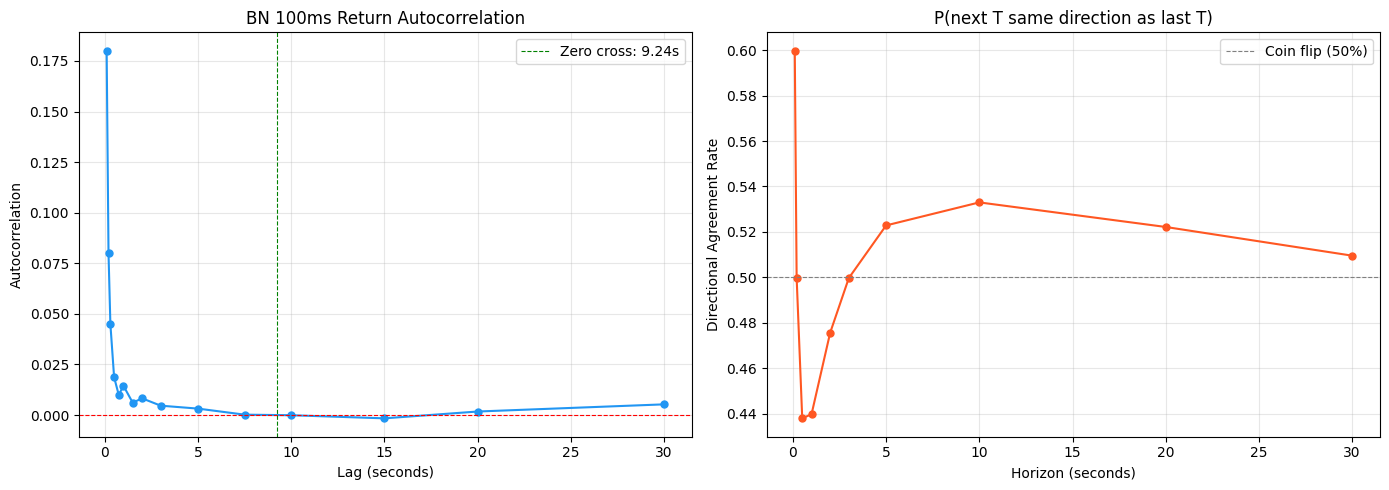

In [2]:
# ── Step 1: Bucket into 100ms bars ────────────────────────────────────
BUCKET_MS = 100
t0 = bn_times[0]
t_end = bn_times[-1]
n_buckets = int((t_end - t0) / BUCKET_MS) + 1

bucket_idx = ((bn_times - t0) / BUCKET_MS).astype(np.int64)
bucket_idx = np.clip(bucket_idx, 0, n_buckets - 1)

# Last price per bucket (fast)
bucket_price = np.full(n_buckets, np.nan)
# Forward fill: iterate and assign last price per bucket
for i in range(len(bn_times)):
    bucket_price[bucket_idx[i]] = bn_prices[i]

# Forward fill NaN buckets (no trades in that 100ms)
mask = np.isnan(bucket_price)
idx_fill = np.where(~mask, np.arange(n_buckets), 0)
np.maximum.accumulate(idx_fill, out=idx_fill)
bucket_price = bucket_price[idx_fill]

# Log returns between consecutive buckets
log_ret = np.diff(np.log(bucket_price))
# Remove any NaN or inf
valid = np.isfinite(log_ret)
log_ret_clean = log_ret[valid]

print(f'Buckets: {n_buckets:,} ({BUCKET_MS}ms each)')
print(f'Valid returns: {len(log_ret_clean):,}')
print(f'Return std per 100ms: {np.std(log_ret_clean)*10000:.4f} bps')

# ── Step 2: Autocorrelation at various lags ──────────────────────────
# Lag in buckets: 1 bucket = 100ms
lags_ms = [100, 200, 300, 500, 750, 1000, 1500, 2000, 3000, 5000,
           7500, 10000, 15000, 20000, 30000]
lags_buckets = [l // BUCKET_MS for l in lags_ms]

acf_values = []
n_ret = len(log_ret_clean)
mean_r = np.mean(log_ret_clean)
var_r = np.var(log_ret_clean)

for lag_b, lag_ms in zip(lags_buckets, lags_ms):
    if lag_b >= n_ret:
        acf_values.append(np.nan)
        continue
    cov = np.mean((log_ret_clean[lag_b:] - mean_r) * (log_ret_clean[:-lag_b] - mean_r))
    acf_values.append(cov / var_r)

print(f'\n{"Lag (ms)":>10} {"Lag (s)":>8} {"ACF":>10}')
print('─' * 32)
for lag_ms, acf in zip(lags_ms, acf_values):
    print(f'{lag_ms:>10} {lag_ms/1000:>8.1f} {acf:>+10.6f}')

# Find zero crossing
acf_arr = np.array(acf_values)
lags_arr = np.array(lags_ms, dtype=float)
zero_cross = None
for i in range(len(acf_arr) - 1):
    if acf_arr[i] > 0 and acf_arr[i+1] <= 0:
        # Linear interpolation
        frac = acf_arr[i] / (acf_arr[i] - acf_arr[i+1])
        zero_cross = lags_arr[i] + frac * (lags_arr[i+1] - lags_arr[i])
        break

if zero_cross:
    print(f'\nMomentum zero crossing: ~{zero_cross:.0f} ms ({zero_cross/1000:.2f} s)')
else:
    print(f'\nNo zero crossing found — momentum persists beyond 30s or is always negative')

# ── Step 3: Directional agreement rate ───────────────────────────────
# For horizon T: does sign(return over last T) == sign(return over next T)?
horizons_ms = [100, 200, 500, 1000, 2000, 3000, 5000, 10000, 20000, 30000]

print(f'\n{"Horizon":>10} {"Agreement":>10} {"N pairs":>10}')
print('─' * 34)

agreement_rates = []
for h_ms in horizons_ms:
    h_b = h_ms // BUCKET_MS
    if 2 * h_b >= len(log_ret_clean):
        agreement_rates.append(np.nan)
        continue

    # Return over window of h_b buckets
    # past return: sum of log_ret[i-h_b:i], future: sum of log_ret[i:i+h_b]
    cumret = np.cumsum(np.concatenate([[0], log_ret_clean]))
    # past return ending at i: cumret[i] - cumret[i-h_b]
    # future return starting at i: cumret[i+h_b] - cumret[i]
    i_start = h_b
    i_end = len(cumret) - h_b
    if i_end <= i_start:
        agreement_rates.append(np.nan)
        continue

    idx = np.arange(i_start, i_end)
    past_ret = cumret[idx] - cumret[idx - h_b]
    future_ret = cumret[idx + h_b] - cumret[idx]

    # Agreement: same sign
    agree = (past_ret > 0) == (future_ret > 0)
    # Exclude cases where either is exactly 0
    nonzero = (past_ret != 0) & (future_ret != 0)
    rate = np.mean(agree[nonzero])
    agreement_rates.append(rate)

    print(f'{h_ms:>9}ms {rate:>9.2%} {nonzero.sum():>10,}')

# ── Plot ─────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# ACF plot
ax1.plot([l/1000 for l in lags_ms], acf_values, 'o-', color='#2196F3', markersize=5)
ax1.axhline(0, color='red', linewidth=0.8, linestyle='--')
if zero_cross:
    ax1.axvline(zero_cross/1000, color='green', linewidth=0.8, linestyle='--',
                label=f'Zero cross: {zero_cross/1000:.2f}s')
ax1.set_xlabel('Lag (seconds)')
ax1.set_ylabel('Autocorrelation')
ax1.set_title('BN 100ms Return Autocorrelation')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Agreement plot
valid_h = [(h, a) for h, a in zip(horizons_ms, agreement_rates) if not np.isnan(a)]
ax2.plot([h/1000 for h, _ in valid_h], [a for _, a in valid_h], 'o-', color='#FF5722', markersize=5)
ax2.axhline(0.5, color='gray', linewidth=0.8, linestyle='--', label='Coin flip (50%)')
ax2.set_xlabel('Horizon (seconds)')
ax2.set_ylabel('Directional Agreement Rate')
ax2.set_title('P(next T same direction as last T)')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/04_momentum.png', dpi=130, bbox_inches='tight')
plt.show()

## Cell B — Realized Volatility Window Comparison
Compute rolling RV at several windows. Bucket into quintiles.
Measure how well each window separates the return distribution over the next 60s.

1-second bars: 779,162
RV window   5s: 779,156 valid, median=0.36 bps, p90=2.24 bps
RV window  10s: 779,151 valid, median=1.00 bps, p90=3.17 bps
RV window  30s: 779,131 valid, median=2.18 bps, p90=5.43 bps
RV window  60s: 779,101 valid, median=3.28 bps, p90=7.67 bps
RV window 120s: 779,041 valid, median=4.88 bps, p90=10.79 bps
RV window 300s: 778,861 valid, median=8.06 bps, p90=17.09 bps

── Quintile Separation (future 60s return std in bps) ──

  Window   Q1(calm)         Q2         Q3         Q4   Q5(wild)  Ratio Q5/Q1
────────────────────────────────────────────────────────────────────────
      5s       4.68       4.81       5.59       6.66       9.78         2.09x
     10s       4.35       4.65       5.70       6.48      10.07         2.31x
     30s       3.64       5.25       5.27       6.31      10.39         2.85x
     60s       3.36       4.64       5.59       6.32      10.60         3.15x
    120s       3.25       4.30       5.28       6.22      10.99         3.38x
    300s  

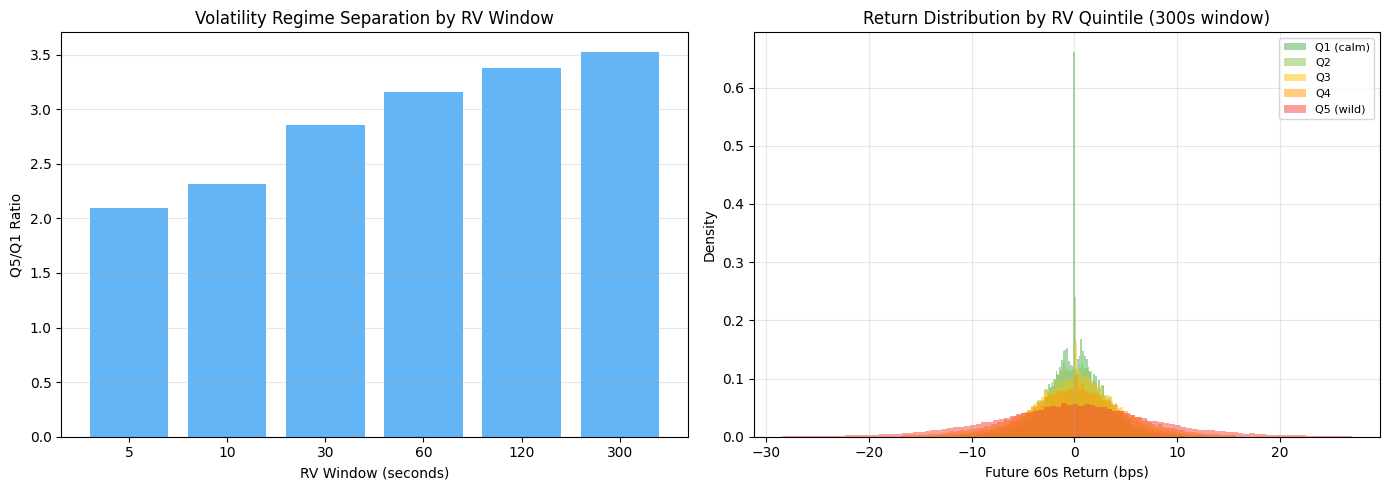


── Summary ──
Best RV window: 300s


In [3]:
# ── Compute RV at different windows ───────────────────────────────────
# We work at 1-second resolution for manageability
# Bucket BN into 1s bars first

BUCKET_1S = 1000
t0 = bn_times[0]
n_1s = int((bn_times[-1] - t0) / BUCKET_1S) + 1

bucket_idx_1s = ((bn_times - t0) / BUCKET_1S).astype(np.int64)
bucket_idx_1s = np.clip(bucket_idx_1s, 0, n_1s - 1)

price_1s = np.full(n_1s, np.nan)
for i in range(len(bn_times)):
    price_1s[bucket_idx_1s[i]] = bn_prices[i]

# Forward fill
mask = np.isnan(price_1s)
idx_fill = np.where(~mask, np.arange(n_1s), 0)
np.maximum.accumulate(idx_fill, out=idx_fill)
price_1s = price_1s[idx_fill]

logret_1s = np.diff(np.log(price_1s))
print(f'1-second bars: {n_1s:,}')

# ── RV at different windows ──────────────────────────────────────────
rv_windows_s = [5, 10, 30, 60, 120, 300]
FUTURE_HORIZON_S = 60  # measure next-60s return std per quintile

# Compute rolling RV for each window
# RV = sqrt(sum of squared log returns over window)
rv_dict = {}
for w in rv_windows_s:
    squared = logret_1s ** 2
    cumsum_sq = np.cumsum(np.concatenate([[0], squared]))
    # RV at index i = sqrt(sum of squared returns from i-w to i)
    rv = np.full(len(logret_1s), np.nan)
    for i in range(w, len(logret_1s)):
        rv[i] = np.sqrt(cumsum_sq[i+1] - cumsum_sq[i+1-w])
    rv_dict[w] = rv
    valid_count = np.sum(~np.isnan(rv))
    print(f'RV window {w:>3}s: {valid_count:,} valid, '
          f'median={np.nanmedian(rv)*10000:.2f} bps, '
          f'p90={np.nanpercentile(rv, 90)*10000:.2f} bps')

# ── For each window, bucket into quintiles, measure future return std ─
# Future return over next FUTURE_HORIZON_S seconds
cumlogret = np.cumsum(np.concatenate([[0], logret_1s]))
future_ret = np.full(len(logret_1s), np.nan)
for i in range(len(logret_1s) - FUTURE_HORIZON_S):
    future_ret[i] = cumlogret[i + 1 + FUTURE_HORIZON_S] - cumlogret[i + 1]

future_ret_bps = future_ret * 10_000

print(f'\n── Quintile Separation (future {FUTURE_HORIZON_S}s return std in bps) ──')
print(f'\n{"Window":>8} {"Q1(calm)":>10} {"Q2":>10} {"Q3":>10} {"Q4":>10} {"Q5(wild)":>10} {"Ratio Q5/Q1":>12}')
print('─' * 72)

separation_scores = {}

for w in rv_windows_s:
    rv = rv_dict[w]
    # Need both RV and future return valid
    valid = ~np.isnan(rv) & ~np.isnan(future_ret_bps)
    rv_v = rv[valid]
    fr_v = future_ret_bps[valid]

    # Quintile boundaries
    q_edges = np.percentile(rv_v, [0, 20, 40, 60, 80, 100])
    q_stds = []
    for qi in range(5):
        mask_q = (rv_v >= q_edges[qi]) & (rv_v < q_edges[qi+1] + (1e-10 if qi == 4 else 0))
        q_stds.append(np.std(fr_v[mask_q]))

    ratio = q_stds[4] / q_stds[0] if q_stds[0] > 0 else np.nan
    separation_scores[w] = ratio

    print(f'{w:>7}s {q_stds[0]:>10.2f} {q_stds[1]:>10.2f} {q_stds[2]:>10.2f} '
          f'{q_stds[3]:>10.2f} {q_stds[4]:>10.2f} {ratio:>12.2f}x')

best_w = max(separation_scores, key=separation_scores.get)
print(f'\nBest separation: {best_w}s window (Q5/Q1 = {separation_scores[best_w]:.2f}x)')

# ── Stability check: first half vs second half ───────────────────────
print(f'\n── Stability Check (first half vs second half) ──')
print(f'{"Window":>8} {"Q5/Q1 1st":>12} {"Q5/Q1 2nd":>12} {"Drift":>8}')
print('─' * 44)

for w in rv_windows_s:
    rv = rv_dict[w]
    valid = ~np.isnan(rv) & ~np.isnan(future_ret_bps)

    # Find indices of valid data
    valid_idx = np.where(valid)[0]
    mid = len(valid_idx) // 2

    ratios = []
    for half_idx in [valid_idx[:mid], valid_idx[mid:]]:
        rv_h = rv[half_idx]
        fr_h = future_ret_bps[half_idx]
        q_edges = np.percentile(rv_h, [0, 20, 80, 100])
        q1_mask = rv_h <= q_edges[1]
        q5_mask = rv_h >= q_edges[2]
        r = np.std(fr_h[q5_mask]) / np.std(fr_h[q1_mask]) if np.std(fr_h[q1_mask]) > 0 else np.nan
        ratios.append(r)

    drift = abs(ratios[0] - ratios[1]) / np.mean(ratios) * 100
    print(f'{w:>7}s {ratios[0]:>12.2f}x {ratios[1]:>12.2f}x {drift:>7.1f}%')

# ── Plot ─────────────────────────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Separation scores
ax1.bar([str(w) for w in rv_windows_s],
        [separation_scores[w] for w in rv_windows_s],
        color='#2196F3', alpha=0.7)
ax1.set_xlabel('RV Window (seconds)')
ax1.set_ylabel('Q5/Q1 Ratio')
ax1.set_title('Volatility Regime Separation by RV Window')
ax1.grid(True, alpha=0.3, axis='y')

# Show quintile stds for best window
rv_best = rv_dict[best_w]
valid = ~np.isnan(rv_best) & ~np.isnan(future_ret_bps)
rv_v = rv_best[valid]
fr_v = future_ret_bps[valid]
q_edges = np.percentile(rv_v, [0, 20, 40, 60, 80, 100])

colors = ['#4CAF50', '#8BC34A', '#FFC107', '#FF9800', '#F44336']
labels = ['Q1 (calm)', 'Q2', 'Q3', 'Q4', 'Q5 (wild)']

for qi in range(5):
    mask_q = (rv_v >= q_edges[qi]) & (rv_v < q_edges[qi+1] + (1e-10 if qi == 4 else 0))
    data = fr_v[mask_q]
    # Clip for visibility
    data_clip = data[(data > np.percentile(data, 1)) & (data < np.percentile(data, 99))]
    ax2.hist(data_clip, bins=100, alpha=0.5, color=colors[qi], label=labels[qi], density=True)

ax2.set_xlabel(f'Future {FUTURE_HORIZON_S}s Return (bps)')
ax2.set_ylabel('Density')
ax2.set_title(f'Return Distribution by RV Quintile ({best_w}s window)')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/04_volatility_window.png', dpi=130, bbox_inches='tight')
plt.show()

print(f'\n── Summary ──')
print(f'Best RV window: {best_w}s')

## Reading the results

**A. Momentum.** The autocorrelation of 100 ms returns is +0.180 at one lag (100 ms), +0.080 at two lags, +0.045 at three,
+0.019 at 0.5 s, and between -0.002 and +0.005 from 7.5 s to 30 s. The printed "zero crossing at 9.24 s" is a linear
interpolation between +0.0002 (7.5 s) and -0.0001 (10 s), so it carries no meaning.

The same-sign rate (does the next T-second move have the same sign as the last T-second move, zero moves excluded?) is
60.0% at 100 ms (only 271,464 non-zero pairs, because most 100 ms buckets contain no trade), 50.0% at 200 ms,
**below 50%** from 0.5 s to 2 s (43.8% at 0.5 s, 44.0% at 1 s, 47.6% at 2 s), 50.0% at 3 s, and above 50% from 5 s to 30 s
with a peak of 53.3% at 10 s (52.3% at 5 s, 52.2% at 20 s, 51.0% at 30 s). I did not investigate the sub-second pattern
(a reversal at 0.5 to 2 s). At horizons of 3 s or more the largest deviation from a coin flip is 3.3 points, so I did
**not** add a momentum axis to the grid. These are overlapping samples, so the large N overstates the precision.

**B. Volatility window.** Longer windows separate calm from wild regimes better (Q5/Q1 ratio of the next-60 s std:
2.09× with a 5 s window, 3.53× with 300 s), but the separation is also less stable between the first and the second half
of the sample. The notebook's drift measure (difference between the halves relative to their average) is 36.5% for 5 s
and 50.6% for 300 s, and every window's Q5/Q1 ratio was lower in the second half (for 300 s: 4.34× then 2.59×).
The script's own summary printed "Best RV window: 300s"; I used **60 s** (3.15×, drift 46.5%) as a compromise, which is a
judgement call rather than a result.